# FlightWise: from raw flights to an explorable dashboard

**July–September 2025 · Student analysis notebook · Visual review**

This notebook reads the already downloaded BTS ZIP files. It shows what is missing or invalid, explains each cleaning choice, builds summaries from the cleaned rows, and explores the results. The three dashboard previews use the same D3 chart modules intended for the later web app. The other plots help us investigate the data.

Run from the project root after installing the notebook requirements and building the local D3 bundle. The original ZIP files are never changed. Times refer to **scheduled local departure time**, not actual departure or UTC time. The quarter does not represent the whole year.

## 1. Setup and source files

The flight data and airport reference came from the U.S. Bureau of Transportation Statistics (BTS). See `data/manifest.json` for original URLs, download dates and hashes. The ZIP files already exist locally; this notebook does not download them.

For a reporting airline's full name, the later chart uses the [DOT 2025 reporting-airline list](https://www.transportation.gov/sites/dot.gov/files/2025-09/August%202025%20ATCR%20-%20June%202025%20and%20Jan-Jun%20Data.pdf). A reporting airline may differ from the brand that sold a ticket. The map uses [U.S. Census state outlines distributed by us-atlas](https://github.com/topojson/us-atlas).

In [1]:
from pathlib import Path
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'data/raw').is_dir():
    raise FileNotFoundError('Open this notebook from the flightwise project or notebooks folder')
YEAR = 2025
MONTHS = [7, 8, 9]
PERIOD = 'July–September 2025'

mkdir -p failed for path C:\Users\nguye\.matplotlib: [WinError 5] Access is denied: 'C:\\Users\\nguye\\.matplotlib'


Matplotlib created a temporary cache directory at C:\Users\nguye\AppData\Local\Temp\matplotlib-s_imq4mn because there was an issue with the default path (C:\Users\nguye\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


**Columns used below.** These are the source fields and the counts we calculate later.

In [2]:
FLIGHT_COLUMNS = ['FlightDate', 'DayOfWeek', 'Reporting_Airline',
                  'OriginAirportID', 'OriginAirportSeqID', 'Origin',
                  'DestAirportID', 'Dest', 'CRSDepTime', 'ArrDelay',
                  'ArrDel15', 'Cancelled', 'Diverted']
AIRPORT_COLUMNS = ['AIRPORT_SEQ_ID', 'AIRPORT_ID', 'AIRPORT',
                   'DISPLAY_AIRPORT_NAME', 'LATITUDE', 'LONGITUDE',
                   'AIRPORT_START_DATE', 'AIRPORT_THRU_DATE',
                   'AIRPORT_STATE_CODE', 'AIRPORT_COUNTRY_CODE_ISO']
COUNT_COLUMNS = ['scheduled_count', 'cancelled_count', 'diverted_count',
                 'cancellation_eligible_count', 'arrival_eligible_count',
                 'late_count', 'excluded_arrival_count', 'invalid_time_count',
                 'unmapped_count']
print('Months:', MONTHS)
print('Raw flight files:', len(list((ROOT / 'data/raw').glob('*2025_*.zip'))))

Months: [7, 8, 9]
Raw flight files: 3


## 2. Inspect and clean the airport reference

The reference supplies names and map coordinates. Airport sequence ID is the exact join key. We convert identifiers and coordinates to numbers, dates to dates, and inspect missing or out-of-range coordinates. A row without a usable map position cannot help the map, so we remove it from the *working reference* after showing it. The raw ZIP stays untouched.

**Read the original airport reference.** Keep `raw_airports` untouched so the conversion is visible.

In [3]:
reference_path = ROOT / 'data/raw/airport_coordinates.zip'
with zipfile.ZipFile(reference_path) as archive:
    csv_name = next(name for name in archive.namelist() if name.lower().endswith('.csv'))
    with archive.open(csv_name) as csv_file:
        raw_airports = pd.read_csv(csv_file, usecols=AIRPORT_COLUMNS, dtype='string')

**Convert the fields used for matching and plotting.**

In [4]:
airports = raw_airports.copy()
for column in ['AIRPORT_SEQ_ID', 'AIRPORT_ID', 'LATITUDE', 'LONGITUDE']:
    airports[column] = pd.to_numeric(airports[column], errors='coerce')
for column in ['AIRPORT_START_DATE', 'AIRPORT_THRU_DATE']:
    airports[column] = pd.to_datetime(airports[column], errors='coerce', format='mixed')
display(raw_airports[['LATITUDE', 'AIRPORT_START_DATE']].head())
display(airports[['LATITUDE', 'AIRPORT_START_DATE']].head())

,LATITUDE,AIRPORT_START_DATE
0,58.10944444,7/1/2007 12:00:00 AM
1,65.54805556,7/1/2007 12:00:00 AM
2,68.08333333,7/1/2007 12:00:00 AM
3,67.57000000,8/1/2007 12:00:00 AM
4,57.74527778,10/1/2007 12:00:00 AM


,LATITUDE,AIRPORT_START_DATE
0,58.109444,2007-07-01
1,65.548056,2007-07-01
2,68.083333,2007-07-01
3,67.57,2007-08-01
4,57.745278,2007-10-01


**Inspect missing coordinates and key problems before changing the working copy.**

In [5]:
bad_coordinates = (~airports.LATITUDE.between(-90, 90) |
                   ~airports.LONGITUDE.between(-180, 180) |
                   (airports.LATITUDE.eq(0) & airports.LONGITUDE.eq(0)))
bad_coordinates = bad_coordinates.fillna(True)
reference_check = pd.DataFrame([{
    'reference_rows_before': len(airports),
    'missing_latitude': int(airports.LATITUDE.isna().sum()),
    'missing_longitude': int(airports.LONGITUDE.isna().sum()),
    'invalid_coordinate_rows': int(bad_coordinates.sum()),
    'duplicate_sequence_ids': int(airports.AIRPORT_SEQ_ID.duplicated().sum()),
    'invalid_numeric_ids': int((airports.AIRPORT_SEQ_ID.isna() | airports.AIRPORT_ID.isna() |
        airports.AIRPORT_SEQ_ID.le(0) | airports.AIRPORT_ID.le(0) |
        airports.AIRPORT_SEQ_ID.ne(airports.AIRPORT_SEQ_ID.round()) |
        airports.AIRPORT_ID.ne(airports.AIRPORT_ID.round())).sum()),
}])
display(reference_check)
display(airports.loc[bad_coordinates, ['AIRPORT_SEQ_ID', 'AIRPORT', 'DISPLAY_AIRPORT_NAME', 'LATITUDE', 'LONGITUDE']])

,reference_rows_before,missing_latitude,missing_longitude,invalid_coordinate_rows,duplicate_sequence_ids,invalid_numeric_ids
0,20298,1,1,1,0,0


,AIRPORT_SEQ_ID,AIRPORT,DISPLAY_AIRPORT_NAME,LATITUDE,LONGITUDE
20297,9999901,ZZZ,Unknown Point in Alaska,<NA>,<NA>


**Remove only unusable coordinate rows** from the working reference after the evidence above.

In [6]:
if reference_check[['duplicate_sequence_ids', 'invalid_numeric_ids']].sum(axis=1).iloc[0]:
    raise ValueError('Resolve airport reference keys before joining flights')
airports = airports.loc[~bad_coordinates].copy()
airports[['AIRPORT_SEQ_ID', 'AIRPORT_ID']] = airports[['AIRPORT_SEQ_ID', 'AIRPORT_ID']].astype('int64')
print('Reference rows after removing unusable coordinates:', len(airports))

Reference rows after removing unusable coordinates: 20297


## 3. Read, inspect and clean July, August and September

We do the same visible steps for each month. The displayed check table counts missing values and failed conversions before the removal. `2400` lies outside our accepted 00:00–23:59 scheduled-time range, so its row is removed. A row with both arrival fields missing **and** neither cancelled nor diverted has no explained arrival outcome, so it is removed. Cancelled and diverted flights with missing arrival measurements are retained for their disruption counts. Their arrival-late status remains unknown.

We keep separate `cleaned_flights` and `arrival_flights` for each month. The first retains cancellations and diversions; the second contains only usable ordinary arrivals. The dashboard geography is the contiguous U.S., Alaska and Hawaii, by **origin** airport. Territory-origin flights are counted and reported below, then removed from the dashboard population. Destinations are not restricted. This is a geographic analysis choice, not a claim that those flights are invalid.

If `ArrDel15` is missing but `ArrDelay` contains minutes, the notebook derives the 15-minute flag. The inspection table counts how often this occurs; it is zero in the current three files. A missing field is never automatically read as on time.

In [7]:
def read_month(month):
    path = ROOT / f'data/raw/On_Time_Reporting_Carrier_On_Time_Performance_1987_present_{YEAR}_{month}.zip'
    with zipfile.ZipFile(path) as archive:
        csv_name = next(name for name in archive.namelist() if name.lower().endswith('.csv'))
        with archive.open(csv_name) as csv_file:
            return pd.read_csv(csv_file, usecols=FLIGHT_COLUMNS, dtype='string')

**Parse source text into dates and numbers.** This creates a working copy; raw strings remain available for comparison.

In [8]:
def parse_month(raw):
    parsed = pd.DataFrame(index=raw.index)
    parsed['date'] = pd.to_datetime(raw.FlightDate, errors='coerce')
    parsed['weekday'] = pd.to_numeric(raw.DayOfWeek, errors='coerce')
    parsed['time'] = pd.to_numeric(raw.CRSDepTime, errors='coerce')
    parsed['arrival_minutes'] = pd.to_numeric(raw.ArrDelay, errors='coerce')
    parsed['arrival_flag'] = pd.to_numeric(raw.ArrDel15, errors='coerce')
    parsed['cancelled'] = pd.to_numeric(raw.Cancelled, errors='coerce')
    parsed['diverted'] = pd.to_numeric(raw.Diverted, errors='coerce')
    parsed['origin_id'] = pd.to_numeric(raw.OriginAirportID, errors='coerce')
    parsed['origin_seq_id'] = pd.to_numeric(raw.OriginAirportSeqID, errors='coerce')
    parsed['destination_id'] = pd.to_numeric(raw.DestAirportID, errors='coerce')

    return parsed

**Show the issues found in each month.** The tables appear before any row is removed.

In [9]:
def show_month_issues(raw, parsed, bad_time, unexplained, checks, month):
    print(f'\n{YEAR}-{month:02d}: {len(raw):,} raw flight rows')
    display(pd.DataFrame([checks]).set_index('month').T.rename(columns={month: 'count'}))
    display(pd.DataFrame({'raw_date': raw.FlightDate.head(3), 'parsed_date': parsed.date.head(3),
                          'raw_time': raw.CRSDepTime.head(3), 'parsed_hour': (parsed.time.head(3) // 100)}))
    print('Invalid scheduled times:')
    display(raw.loc[bad_time, ['FlightDate', 'Origin', 'Dest', 'CRSDepTime']].head(5))
    print('Missing arrival outcome with no cancellation or diversion:')
    display(raw.loc[unexplained, ['FlightDate', 'Origin', 'Dest', 'ArrDelay',
                                   'ArrDel15', 'Cancelled', 'Diverted']].head(5))

**Count invalid and missing values.** The same checks run for July, August and September.

In [10]:
def inspect_month(raw, month):
    parsed = parse_month(raw)
    bad_date = parsed.date.isna()
    wrong_month = (~bad_date) & ((parsed.date.dt.year != YEAR) | (parsed.date.dt.month != month))
    wrong_weekday = (~bad_date) & parsed.weekday.ne(parsed.date.dt.dayofweek + 1)
    bad_id = (parsed[['origin_id', 'origin_seq_id', 'destination_id']].isna().any(axis=1) |
              parsed[['origin_id', 'origin_seq_id', 'destination_id']].le(0).any(axis=1) |
              parsed[['origin_id', 'origin_seq_id', 'destination_id']].ne(
                  parsed[['origin_id', 'origin_seq_id', 'destination_id']].round()).any(axis=1))
    valid_time = (parsed.time.notna() & parsed.time.eq(parsed.time.round()) &
                  parsed.time.between(0, 2359) & (parsed.time % 100).lt(60))
    bad_time = ~valid_time
    bad_flag = (~parsed.cancelled.isin([0, 1]) | ~parsed.diverted.isin([0, 1]) |
                (parsed.arrival_flag.notna() & ~parsed.arrival_flag.isin([0, 1])))
    conflict = (parsed.arrival_flag.notna() & parsed.arrival_minutes.notna() &
                parsed.arrival_flag.ne(parsed.arrival_minutes.ge(15)))
    missing_arrival = parsed.arrival_minutes.isna() & parsed.arrival_flag.isna()
    unexplained = missing_arrival & parsed.cancelled.eq(0) & parsed.diverted.eq(0)
    fallback = parsed.arrival_flag.isna() & parsed.arrival_minutes.notna()

    checks = {'month': month, 'raw_rows': len(raw),
        'missing_raw_dates': int(raw.FlightDate.isna().sum()),
        'failed_date_parsing': int((raw.FlightDate.notna() & bad_date).sum()),
        'outside_expected_month': int(wrong_month.sum()),
        'weekday_mismatches': int(wrong_weekday.sum()),
        'invalid_airport_ids': int(bad_id.sum()),
        'missing_raw_times': int(raw.CRSDepTime.isna().sum()),
        'failed_time_parsing': int((raw.CRSDepTime.notna() & parsed.time.isna()).sum()),
        'invalid_or_missing_times': int(bad_time.sum()),
        'missing_raw_arrival_minutes': int(raw.ArrDelay.isna().sum()),
        'failed_arrival_minutes_parsing': int((raw.ArrDelay.notna() & parsed.arrival_minutes.isna()).sum()),
        'missing_arrival_minutes': int(parsed.arrival_minutes.isna().sum()),
        'missing_raw_arrival_flags': int(raw.ArrDel15.isna().sum()),
        'failed_arrival_flag_parsing': int((raw.ArrDel15.notna() & parsed.arrival_flag.isna()).sum()),
        'missing_arrival_flags': int(parsed.arrival_flag.isna().sum()),
        'missing_arrival_cancelled': int((missing_arrival & parsed.cancelled.eq(1)).sum()),
        'missing_arrival_diverted': int((missing_arrival & parsed.cancelled.eq(0) & parsed.diverted.eq(1)).sum()),
        'missing_arrival_unexplained': int(unexplained.sum()),
        'flags_derived_from_minutes': int(fallback.sum()),
        'delay_flag_conflicts': int(conflict.sum()),
        'invalid_status_flags': int(bad_flag.sum()),
        'duplicate_selected_rows': int(raw.duplicated().sum())}

    show_month_issues(raw, parsed, bad_time, unexplained, checks, month)
    if bad_date.any() or wrong_month.any() or wrong_weekday.any() or bad_id.any() or bad_flag.any() or conflict.any():
        raise ValueError(f'Review invalid dates, IDs or statuses in month {month}')
    return parsed, bad_time, unexplained, checks

**Clean the working month.** Remove the displayed invalid-time and unexplained-outcome rows; keep cancellations and diversions for their own measures.

In [11]:
def clean_month(raw, parsed, bad_time, unexplained):
    # Keep cancelled and diverted flights for disruption statistics.
    remove = bad_time | unexplained
    flights = raw.loc[~remove].copy()
    values = parsed.loc[~remove]
    flights['flight_date'] = values.date
    flights['origin_id'] = values.origin_id.astype('int64')
    flights['origin_seq_id'] = values.origin_seq_id.astype('int64')
    flights['weekday'] = values.weekday.astype('int64')
    flights['hour'] = (values.time // 100).astype('int64')
    flights['arrival_minutes'] = values.arrival_minutes
    flights['cancelled'] = values.cancelled.astype('int64')
    flights['diverted'] = values.diverted.astype('int64')
    derived = values.arrival_minutes.ge(15).where(values.arrival_minutes.notna()).astype('Int64')
    flights['late_flag'] = values.arrival_flag.fillna(derived)
    return flights

**Match airports and define the chart population.** Only eligible completed arrivals contribute to the late-arrival rate.

In [12]:
def join_and_scope(flights, airports):
    joined = flights.merge(airports, how='left', left_on='origin_seq_id',
                           right_on='AIRPORT_SEQ_ID', validate='many_to_one', indicator=True)
    if len(joined) != len(flights):
        raise ValueError('Airport join changed flight count')
    matched = joined['_merge'].eq('both')
    if (matched & joined.origin_id.ne(joined.AIRPORT_ID)).any():
        raise ValueError('Airport ID disagrees with sequence ID')
    in_dates = ((joined.AIRPORT_START_DATE.isna() | joined.flight_date.ge(joined.AIRPORT_START_DATE)) &
                (joined.AIRPORT_THRU_DATE.isna() | joined.flight_date.le(joined.AIRPORT_THRU_DATE)))
    mapped = matched & in_dates
    territory = joined.AIRPORT_STATE_CODE.isin(['PR', 'VI', 'TT'])
    scoped = joined.loc[~territory].copy()
    if scoped.AIRPORT_STATE_CODE.isna().any():
        raise ValueError('Unmatched origin airport in dashboard scope')
    scoped['carrier'] = scoped.Reporting_Airline
    scoped['scheduled_count'] = 1
    scoped['cancelled_count'] = scoped.cancelled.eq(1).astype('int64')
    scoped['diverted_count'] = scoped.diverted.eq(1).astype('int64')
    scoped['cancellation_eligible_count'] = 1
    eligible = scoped.cancelled.eq(0) & scoped.diverted.eq(0) & scoped.late_flag.notna()
    scoped['arrival_eligible_count'] = eligible.astype('int64')
    scoped['late_count'] = (eligible & scoped.late_flag.eq(1)).fillna(False).astype('int64')
    scoped['excluded_arrival_count'] = (~eligible).astype('int64')
    scoped['invalid_time_count'] = 0
    scoped['unmapped_count'] = (~mapped.loc[~territory]).astype('int64')
    join_check = {'territory_origin_rows': int(territory.sum()),
                  'unmapped_rows': int((~mapped).sum()),
                  'outside_reference_dates': int((matched & ~in_dates).sum())}
    return scoped, eligible, join_check

**Run those same steps for all three months.** Keep only small monthly summaries after each iteration, so raw months do not accumulate in memory.

In [13]:
monthly_checks, monthly_totals, removal_log = [], [], []
monthly_flight_summaries, monthly_airport_summaries = [], []
monthly_airline_summaries, monthly_delay_bins, airport_details = [], [], []

edges = [-float('inf'), -30, 0, 15, 30, 60, 120, 240, float('inf')]
labels = ['< -30', '-30 to <0', '0 to <15', '15 to <30',
              '30 to <60', '60 to <120', '120 to <240', '240+']

**Read, clean and summarize one month at a time.** Each iteration prints its evidence and before/after counts.

In [14]:
for month in MONTHS:
    raw = read_month(month)
    parsed, bad_time, unexplained, check = inspect_month(raw, month)
    monthly_checks.append(check)
    if bad_time.any():
        removal_log.append({'month': month, 'reason': 'Invalid scheduled HHMM', 'rows': int(bad_time.sum())})
    if unexplained.any():
        removal_log.append({'month': month, 'reason': 'Missing unexplained arrival outcome',
                            'rows': int((unexplained & ~bad_time).sum())})
    cleaned_flights = clean_month(raw, parsed, bad_time, unexplained)
    dashboard_flights, eligible, join_check = join_and_scope(cleaned_flights, airports)
    arrival_flights = dashboard_flights.loc[eligible].copy()

    monthly_totals.append({'month': month, 'raw_rows': len(raw),
        'removed_invalid_time': int(bad_time.sum()),
        'removed_unexplained_arrival': int((unexplained & ~bad_time).sum()),
        'cleaned_rows': len(cleaned_flights), 'dashboard_rows': len(dashboard_flights),
        'eligible_arrival_rows': len(arrival_flights), **join_check,
        **{column: int(dashboard_flights[column].sum()) for column in COUNT_COLUMNS}})
    monthly_flight_summaries.append(dashboard_flights.groupby(
        ['origin_id', 'carrier', 'weekday', 'hour'], as_index=False)[COUNT_COLUMNS].sum())
    monthly_airport_summaries.append(dashboard_flights.groupby('origin_id', as_index=False)[COUNT_COLUMNS].sum())
    monthly_airline_summaries.append(dashboard_flights.groupby('carrier', as_index=False)[COUNT_COLUMNS].sum())
    airport_details.append(dashboard_flights[['origin_id', 'origin_seq_id', 'Origin',
        'DISPLAY_AIRPORT_NAME', 'LATITUDE', 'LONGITUDE', 'AIRPORT_STATE_CODE']].drop_duplicates())
    bins = pd.cut(arrival_flights.arrival_minutes, edges, labels=labels, right=False)
    monthly_delay_bins.append(bins.value_counts(sort=False))
    print(f'Result: {len(raw):,} raw → {len(cleaned_flights):,} cleaned → '
          f'{len(dashboard_flights):,} in geographic scope → {len(arrival_flights):,} eligible arrivals')
    display(dashboard_flights[['FlightDate', 'Origin', 'carrier', 'hour',
        'cancelled_count', 'diverted_count', 'arrival_eligible_count', 'late_count']].head(3))
    del raw, parsed, cleaned_flights, dashboard_flights, arrival_flights


2025-07: 631,428 raw flight rows


month,count
raw_rows,631428
missing_raw_dates,0
failed_date_parsing,0
outside_expected_month,0
weekday_mismatches,0
invalid_airport_ids,0
missing_raw_times,0
failed_time_parsing,0
invalid_or_missing_times,1
missing_raw_arrival_minutes,18617


,raw_date,parsed_date,raw_time,parsed_hour
0,2025-07-23,2025-07-23,0832,8
1,2025-07-24,2025-07-24,0832,8
2,2025-07-25,2025-07-25,0832,8


Invalid scheduled times:


,FlightDate,Origin,Dest,CRSDepTime
249077,2025-07-24,DSM,ORD,2400


Missing arrival outcome with no cancellation or diversion:


... (17 outputs left out)

Missing arrival outcome with no cancellation or diversion:


,FlightDate,Origin,Dest,ArrDelay,ArrDel15,Cancelled,Diverted
410705,2025-09-06,JFK,MVY,<NA>,<NA>,0.00,0.00


Result: 562,439 raw → 562,438 cleaned → 559,992 in geographic scope → 555,895 eligible arrivals


,FlightDate,Origin,carrier,hour,cancelled_count,diverted_count,arrival_eligible_count,late_count
0,2025-09-06,ORD,MQ,18,0,0,1,0
1,2025-09-07,ORD,MQ,19,0,0,1,0
2,2025-09-08,ORD,MQ,19,0,0,1,1


The row count falls for **specific reasons**, rather than because every missing field is bad. Cancelled and diverted flights have expected missing arrival measurements and remain in the dashboard population. We filter them out only when creating the eligible-arrival population. The next table reconciles raw rows, removals, geographic scope and eligible arrivals.

**Reconcile populations.** Each row removal and scope change has a named count.

In [15]:
checks = pd.DataFrame(monthly_checks).set_index('month')
row_flow = pd.DataFrame(monthly_totals).set_index('month')
display(row_flow[['raw_rows', 'removed_invalid_time', 'removed_unexplained_arrival',
                  'cleaned_rows', 'territory_origin_rows', 'dashboard_rows',
                  'eligible_arrival_rows', 'cancelled_count', 'diverted_count',
                  'excluded_arrival_count', 'unmapped_rows']])
display(pd.DataFrame(removal_log))

,raw_rows,removed_invalid_time,removed_unexplained_arrival,cleaned_rows,territory_origin_rows,dashboard_rows,eligible_arrival_rows,cancelled_count,diverted_count,excluded_arrival_count,unmapped_rows
month,,,,,,,,,,,
7,631428,1,0,631427,4489,626938,608427,15408,3103,18511,0
8,602378,0,0,602378,3859,598519,589954,6432,2133,8565,0
9,562439,0,1,562438,2446,559992,555895,2885,1212,4097,0


,month,reason,rows
0,7,Invalid scheduled HHMM,1
1,9,Missing unexplained arrival outcome,1


**Review issue counts and rates.** Counts show how many rows were affected; percentages use the original monthly row counts. Issue categories can overlap.

In [16]:
issue_columns = ['failed_date_parsing', 'outside_expected_month', 'weekday_mismatches',
                 'invalid_airport_ids', 'missing_raw_times', 'failed_time_parsing',
                 'invalid_or_missing_times',
                 'missing_raw_arrival_minutes', 'failed_arrival_minutes_parsing',
                 'missing_arrival_minutes', 'missing_raw_arrival_flags',
                 'failed_arrival_flag_parsing', 'missing_arrival_flags',
                 'missing_arrival_unexplained', 'flags_derived_from_minutes',
                 'delay_flag_conflicts', 'invalid_status_flags', 'duplicate_selected_rows']
print('Affected row counts by month (issue categories may overlap):')
display(checks[issue_columns].T)

issue_percent = checks[issue_columns].div(checks.raw_rows, axis=0).mul(100).round(3)
print('Percent of original flight rows in each month (columns may overlap):')
display(issue_percent.T)

Affected row counts by month (issue categories may overlap):


month,7,8,9
failed_date_parsing,0,0,0
outside_expected_month,0,0,0
weekday_mismatches,0,0,0
invalid_airport_ids,0,0,0
missing_raw_times,0,0,0
failed_time_parsing,0,0,0
invalid_or_missing_times,1,0,0
missing_raw_arrival_minutes,18617,8645,4111
failed_arrival_minutes_parsing,0,0,0
missing_arrival_minutes,18617,8645,4111


Percent of original flight rows in each month (columns may overlap):


month,7,8,9
failed_date_parsing,0.000,0.000,0.000
outside_expected_month,0.000,0.000,0.000
weekday_mismatches,0.000,0.000,0.000
invalid_airport_ids,0.000,0.000,0.000
missing_raw_times,0.000,0.000,0.000
failed_time_parsing,0.000,0.000,0.000
invalid_or_missing_times,0.000,0.000,0.000
missing_raw_arrival_minutes,2.948,1.435,0.731
failed_arrival_minutes_parsing,0.000,0.000,0.000
missing_arrival_minutes,2.948,1.435,0.731


**Check the before and after totals.**

In [28]:
print('Overall raw rows:', int(row_flow.raw_rows.sum()))
print('Overall removed flight rows:', int(row_flow.removed_invalid_time.sum() + row_flow.removed_unexplained_arrival.sum()))
print('Rows outside selected origin geography:', int(row_flow.territory_origin_rows.sum()))
print('Dashboard flight rows:', int(row_flow.dashboard_rows.sum()))
if not (row_flow.raw_rows == row_flow.cleaned_rows + row_flow.removed_invalid_time + row_flow.removed_unexplained_arrival).all():
    raise ValueError('Cleaning row totals do not reconcile')
if not (row_flow.cleaned_rows == row_flow.dashboard_rows + row_flow.territory_origin_rows).all():
    raise ValueError('Geographic totals do not reconcile')
if not (row_flow.dashboard_rows == row_flow.eligible_arrival_rows + row_flow.excluded_arrival_count).all():
    raise ValueError('Arrival-eligibility totals do not reconcile')

Overall raw rows: 1796245
Overall removed flight rows: 2
Rows outside selected origin geography: 10794
Dashboard flight rows: 1785449


## 4. Summarize the three months

The flight summary groups by **origin airport, reporting airline, weekday and scheduled departure hour**. We sum flight counts first, then divide to get rates. A zero eligible-arrival denominator gives a missing rate, not 0%. These summaries come from the notebook's cleaned rows; no previously processed table is needed.

In [29]:
flight_summary = pd.concat(monthly_flight_summaries).groupby(
    ['origin_id', 'carrier', 'weekday', 'hour'], as_index=False)[COUNT_COLUMNS].sum()
airport_summary = pd.concat(monthly_airport_summaries).groupby(
    'origin_id', as_index=False)[COUNT_COLUMNS].sum()
airline_summary = pd.concat(monthly_airline_summaries).groupby(
    'carrier', as_index=False)[COUNT_COLUMNS].sum()
airport_names = pd.concat(airport_details).drop_duplicates().rename(columns={
    'Origin': 'origin_code', 'DISPLAY_AIRPORT_NAME': 'name',
    'AIRPORT_STATE_CODE': 'region'})
if airport_names.origin_id.duplicated().any():
    raise ValueError('An origin has multiple coordinate records; inspect before plotting')
map_data = airport_summary.merge(airport_names, on='origin_id', validate='one_to_one')
quarter_totals = airport_summary[COUNT_COLUMNS].sum()
display(pd.DataFrame({'quarter_total': quarter_totals}))
display(flight_summary.head())
print('Airport origins:', len(map_data), '| grouped flight-summary rows:', len(flight_summary))
print('Geographic scope:', ', '.join(sorted(map_data.region.unique())))

,quarter_total
scheduled_count,1785449
cancelled_count,24725
diverted_count,6448
cancellation_eligible_count,1785449
arrival_eligible_count,1754276
late_count,401327
excluded_arrival_count,31173
invalid_time_count,0
unmapped_count,0


,origin_id,carrier,weekday,hour,scheduled_count,cancelled_count,diverted_count,cancellation_eligible_count,arrival_eligible_count,late_count,excluded_arrival_count,invalid_time_count,unmapped_count
0,10135,G4,1,6,13,0,0,13,13,0,0,0,0
1,10135,G4,1,7,2,0,0,2,2,0,0,0,0
2,10135,G4,1,8,13,0,0,13,13,0,0,0,0
3,10135,G4,1,9,11,0,0,11,11,0,0,0,0
4,10135,G4,1,12,6,0,0,6,6,0,0,0,0


Airport origins: 340 | grouped flight-summary rows: 77051
Geographic scope: AK, AL, AR, AZ, CA, CO, CT, FL, GA, HI, IA, ID, IL, IN, KS, KY, LA, MA, MD, ME, MI, MN, MO, MS, MT, NC, ND, NE, NH, NJ, NM, NV, NY, OH, OK, OR, PA, RI, SC, SD, TN, TX, UT, VA, VT, WA, WI, WV, WY


## 5. Explore delay, cancellations and diversions

These are **exploratory notebook plots**, not extra web dashboard views. Late-arrival rate uses eligible arrivals. Cancellation and diversion rates use scheduled flights. Their denominators differ, so we display them separately rather than stacking all three percentages into one measure.

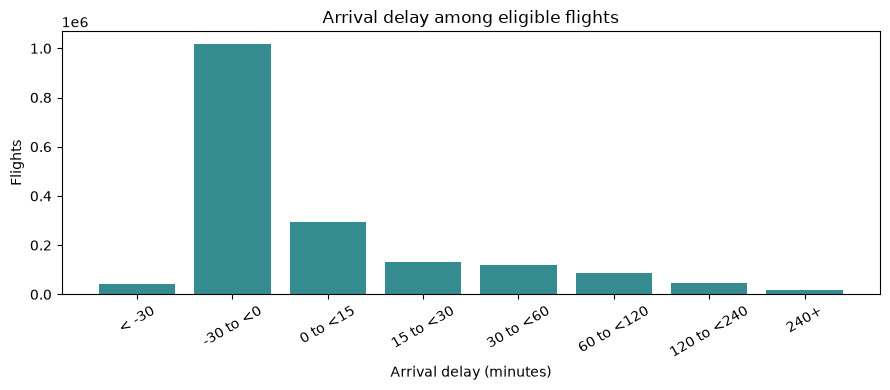

Flights represented in distribution: 1754276


In [30]:
delay_counts = pd.concat(monthly_delay_bins, axis=1).sum(axis=1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(delay_counts.index.astype(str), delay_counts.values, color='#348c91')
ax.set(title='Arrival delay among eligible flights', ylabel='Flights', xlabel='Arrival delay (minutes)')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()
print('Flights represented in distribution:', int(delay_counts.sum()))

,scheduled_count,arrival_eligible_count,late_count,cancelled_count,diverted_count,late_rate,cancellation_rate,diversion_rate
month,,,,,,,,
7,626938,608427,176012,15408,3103,0.289290,0.024577,0.004949
8,598519,589954,132888,6432,2133,0.225251,0.010747,0.003564
9,559992,555895,92427,2885,1212,0.166267,0.005152,0.002164


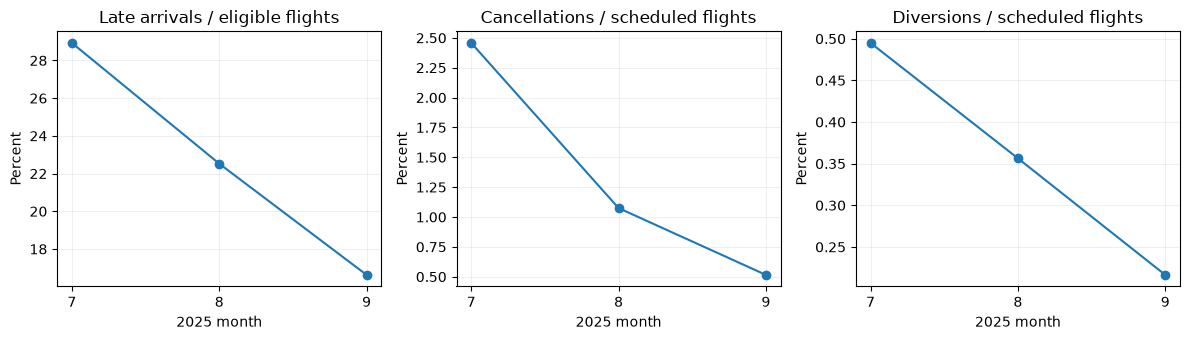

In [31]:
monthly_rates = row_flow.copy()
monthly_rates['late_rate'] = monthly_rates.late_count / monthly_rates.arrival_eligible_count
monthly_rates['cancellation_rate'] = monthly_rates.cancelled_count / monthly_rates.scheduled_count
monthly_rates['diversion_rate'] = monthly_rates.diverted_count / monthly_rates.scheduled_count
display(monthly_rates[['scheduled_count', 'arrival_eligible_count', 'late_count',
                       'cancelled_count', 'diverted_count',
                       'late_rate', 'cancellation_rate', 'diversion_rate']])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, column, title in zip(axes,
        ['late_rate', 'cancellation_rate', 'diversion_rate'],
        ['Late arrivals / eligible flights', 'Cancellations / scheduled flights',
         'Diversions / scheduled flights']):
    ax.plot(monthly_rates.index, monthly_rates[column] * 100, marker='o')
    ax.set(title=title, xlabel='2025 month', ylabel='Percent', xticks=MONTHS)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Which reporting airlines had cancellations or diversions?

The two segments share the scheduled-flight denominator. This plot explores disruptions alongside the main airline late-rate chart; it does not replace that chart or claim one airline is intrinsically better. Route mix, airport mix and coverage differ between airlines.

**Calculate cancellation and diversion shares.** Both use scheduled flights as the denominator.

In [32]:
AIRLINE_NAMES = {'AA':'American Airlines','AS':'Alaska Airlines','B6':'JetBlue Airways',
    'DL':'Delta Air Lines','F9':'Frontier Airlines','G4':'Allegiant Air',
    'HA':'Hawaiian Airlines','MQ':'Envoy Air','NK':'Spirit Airlines',
    'OH':'PSA Airlines','OO':'SkyWest Airlines','UA':'United Airlines',
    'WN':'Southwest Airlines','YX':'Republic Airways'}
airline_disruptions = airline_summary.copy()
airline_disruptions['airline'] = airline_disruptions.carrier.map(AIRLINE_NAMES)
if airline_disruptions.airline.isna().any():
    raise ValueError('Add a verified full name for each reporting airline')
airline_disruptions['cancel_pct'] = 100 * airline_disruptions.cancelled_count / airline_disruptions.scheduled_count
airline_disruptions['divert_pct'] = 100 * airline_disruptions.diverted_count / airline_disruptions.scheduled_count
airline_disruptions = airline_disruptions.sort_values('cancel_pct', ascending=True)
display(airline_disruptions[['airline', 'scheduled_count', 'cancelled_count',
                             'diverted_count', 'cancel_pct', 'divert_pct']])

,airline,scheduled_count,cancelled_count,diverted_count,cancel_pct,divert_pct
5,Allegiant Air,31402,70,102,0.222916,0.324820
6,Hawaiian Airlines,20400,79,15,0.387255,0.073529
12,Southwest Airlines,349506,2305,1156,0.659502,0.330753
3,Delta Air Lines,268257,2087,956,0.777985,0.356375
10,SkyWest Airlines,219432,2052,799,0.935142,0.364122
11,United Airlines,204982,2169,917,1.058142,0.447356
8,Spirit Airlines,48411,542,143,1.119580,0.295387
1,Alaska Airlines,67342,891,182,1.323097,0.270262
7,Envoy Air,79223,1227,264,1.548793,0.333237
4,Frontier Airlines,46602,760,97,1.630831,0.208146


**Plot the two disruption shares together.**

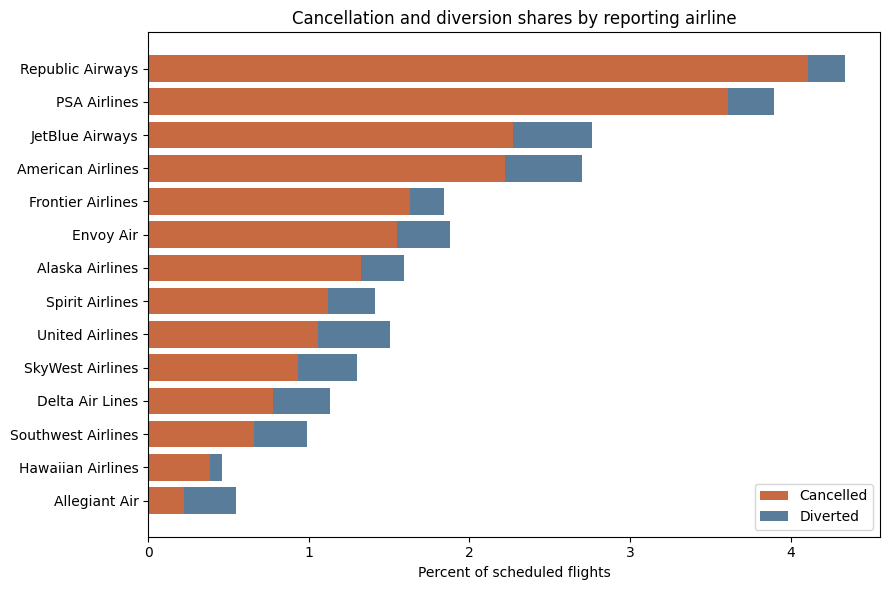

In [22]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(airline_disruptions.airline, airline_disruptions.cancel_pct,
        label='Cancelled', color='#c76a42')
ax.barh(airline_disruptions.airline, airline_disruptions.divert_pct,
        left=airline_disruptions.cancel_pct, label='Diverted', color='#597c9b')
ax.set(xlabel='Percent of scheduled flights',
       title='Cancellation and diversion shares by reporting airline')
ax.legend()
plt.tight_layout()
plt.show()

## 6. When do flights depart, and how often do they arrive late?

This **combined bar-and-line chart** overlays both measures in one plotting area. The bars show each local hour’s share of all scheduled flights on the **left** percentage axis. The line shows late arrivals divided by eligible arrivals in that hour on the **right** percentage axis. Both use the same hour categories, but their denominators differ. A hollow point has fewer than 30 eligible arrivals, and a gap means no late rate is available. These are associations within this quarter, not evidence that departure time caused a delay.

In [23]:
import sys
sys.path.insert(0, str(ROOT))
from notebooks.preview_support import show_d3

hourly = flight_summary.groupby('hour')[COUNT_COLUMNS].sum().reindex(range(24), fill_value=0)
hourly['flight_share'] = hourly.scheduled_count / hourly.scheduled_count.sum()
hourly['late_rate'] = hourly.late_count / hourly.arrival_eligible_count.where(hourly.arrival_eligible_count.gt(0))
display(hourly[['scheduled_count', 'flight_share', 'arrival_eligible_count', 'late_count', 'late_rate']])
show_d3('hourly_overview', hourly.reset_index(), period=PERIOD, origin='ALL')

,scheduled_count,flight_share,arrival_eligible_count,late_count,late_rate
hour,,,,,
0,2794,0.001565,2743,506,0.184470
1,526,0.000295,517,79,0.152805
2,184,0.000103,180,49,0.272222
3,0,0.000000,0,0,NaN
4,11,0.000006,11,2,0.181818
5,47841,0.026795,47191,3364,0.071285
6,123024,0.068904,121228,10220,0.084304
7,131160,0.073461,129574,14431,0.111373
8,124487,0.069723,123208,16131,0.130925


### Does the hourly pattern look different at two airports?

We compare JFK and ATL as examples, with only two lines to keep the figure readable. Check eligible-flight counts before interpreting thinly covered hours. A missing rate stays a gap; a measured hour with few flights is shown but should be treated cautiously.

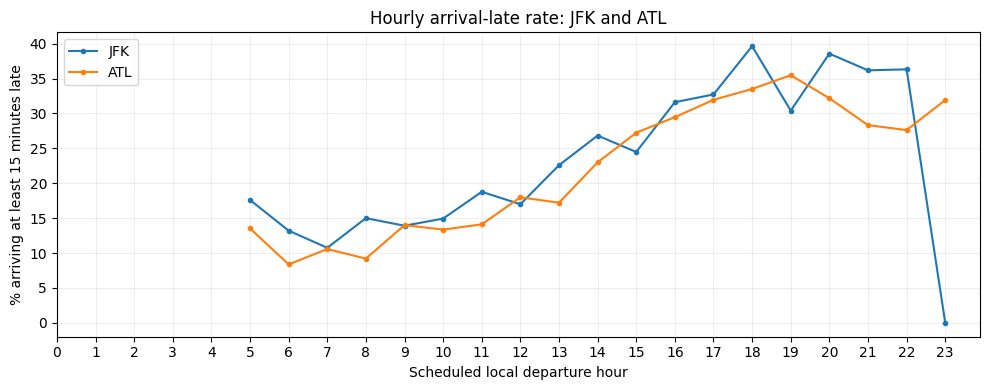

In [24]:
fig, ax = plt.subplots(figsize=(10, 4))
for airport_code in ['JFK', 'ATL']:
    airport_id = map_data.loc[map_data.origin_code.eq(airport_code), 'origin_id'].iloc[0]
    comparison = flight_summary.loc[flight_summary.origin_id.eq(airport_id)].groupby('hour')[COUNT_COLUMNS].sum().reindex(range(24), fill_value=0)
    rate = comparison.late_count / comparison.arrival_eligible_count.where(comparison.arrival_eligible_count.gt(0))
    ax.plot(range(24), rate * 100, marker='o', markersize=3, label=airport_code)
ax.set(xlabel='Scheduled local departure hour', ylabel='% arriving at least 15 minutes late',
       title='Hourly arrival-late rate: JFK and ATL', xticks=range(24))
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Preview the dashboard views in D3

The charts below are previews of the planned web views. Each `show_d3` call passes the DataFrame built in the preceding cell to a locally built JavaScript chart. The notebook uses no exported image as a chart input. The production web app and live linked selection have not been built yet.

### Airport map and a readable airport comparison

The main map is scoped to the contiguous U.S., Alaska and Hawaii. Bubble area shows scheduled flight volume; color shows arrival-late rate. Land and state boundaries provide location context. Insets use different geographic scales. The named-airport comparison below is a separate exploration of the 15 busiest origins, with two aligned bar columns and details on hover/focus.

In [25]:
show_d3('map', map_data, period=PERIOD, volumeMax=int(map_data.scheduled_count.max()))

In [26]:
top_airports = map_data.sort_values('scheduled_count', ascending=False).head(15).copy()
display(top_airports[['origin_code', 'name', 'scheduled_count', 'arrival_eligible_count', 'late_count']])
show_d3('airport_compare', top_airports, title='How do the busiest airports compare?',
        subtitle=f'{PERIOD} · 15 busiest origin airports · hover or focus for exact counts')

,origin_code,name,scheduled_count,arrival_eligible_count,late_count
238,ORD,Chicago O'Hare International,89460,87510,24281
88,DEN,Denver International,84065,83075,24431
20,ATL,Hartsfield-Jackson Atlanta International,81743,80776,18044
89,DFW,Dallas/Fort Worth International,81691,79298,24633
183,LAX,Los Angeles International,48859,48337,8785
69,CLT,Charlotte Douglas International,47267,46546,12111
293,SEA,Seattle/Tacoma International,47099,46553,11660
181,LAS,Harry Reid International,45052,44541,10230
249,PHX,Phoenix Sky Harbor International,43881,43379,8827
203,MCO,Orlando International,37581,37083,10203


### Airport selection → weekday and departure-hour heatmap

Rows are Monday through Sunday; columns are scheduled local hours. JFK is shown first. The second heatmap shows the same calculation across all origins, so you can compare context. Empty cells differ from measured 0% late cells.

In [27]:
CONTEXT_AIRPORT = 'JFK'  # Change to 'ALL' or an origin code from map_data.
airport_id = None if CONTEXT_AIRPORT == 'ALL' else map_data.loc[map_data.origin_code.eq(CONTEXT_AIRPORT), 'origin_id'].iloc[0]
context_rows = flight_summary if airport_id is None else flight_summary.loc[flight_summary.origin_id.eq(airport_id)]
day_hour_index = pd.MultiIndex.from_product([range(1, 8), range(24)], names=['weekday', 'hour'])
heatmap_data = context_rows.groupby(['weekday', 'hour'])[COUNT_COLUMNS].sum().reindex(day_hour_index, fill_value=0).reset_index()
heatmap_data['late_rate'] = heatmap_data.late_count / heatmap_data.arrival_eligible_count.where(heatmap_data.arrival_eligible_count.gt(0))
display(heatmap_data.loc[heatmap_data.hour.isin([8, 17]),
                         ['weekday', 'hour', 'scheduled_count', 'late_count', 'arrival_eligible_count', 'late_rate']])
show_d3('heatmap', heatmap_data, period=PERIOD, origin=CONTEXT_AIRPORT)

,weekday,hour,scheduled_count,late_count,arrival_eligible_count,late_rate
8,1,8,322,37,316,0.117089
17,1,17,256,61,240,0.254167
32,2,8,351,31,351,0.088319
41,2,17,260,65,248,0.262097
56,3,8,328,45,324,0.138889
65,3,17,244,81,229,0.353712
80,4,8,324,63,318,0.198113
89,4,17,253,105,235,0.446809
104,5,8,324,40,317,0.126183
113,5,17,253,76,250,0.304000


In [28]:
all_heatmap = flight_summary.groupby(['weekday', 'hour'])[COUNT_COLUMNS].sum().reindex(day_hour_index, fill_value=0).reset_index()
all_heatmap['late_rate'] = all_heatmap.late_count / all_heatmap.arrival_eligible_count.where(all_heatmap.arrival_eligible_count.gt(0))
show_d3('heatmap', all_heatmap, period=PERIOD, origin='ALL')

### Time selection → airline comparison

This is a preview of the second planned link. Choose exact weekday/hour pairs such as `(1, 8)` for Monday 08:00–08:59. Two tuples mean **either selected cell**, not the Cartesian product of chosen weekdays and hours. In the web app, users will select heatmap cells directly; here we edit the list and rerun the cell. Full names are reporting airlines. The bars sort by late-arrival rate for the current context, with exact counts on hover/focus.

In [29]:
SELECTED_CELLS = [(1, 8)]  # Empty list means all hours in the current airport context.
if SELECTED_CELLS:
    chosen = [(day, hour) in SELECTED_CELLS for day, hour in zip(context_rows.weekday, context_rows.hour)]
    selected_rows = context_rows.loc[chosen]
else:
    selected_rows = context_rows
airline_bars = selected_rows.groupby('carrier', as_index=False)[COUNT_COLUMNS].sum()
airline_bars['airline'] = airline_bars.carrier.map(AIRLINE_NAMES)
airline_bars['late_rate'] = airline_bars.late_count / airline_bars.arrival_eligible_count.where(airline_bars.arrival_eligible_count.gt(0))
display(airline_bars.sort_values('late_rate', ascending=False)[['airline', 'scheduled_count',
    'late_count', 'arrival_eligible_count', 'late_rate', 'cancelled_count', 'diverted_count']])
show_d3('bars', airline_bars,
        period=PERIOD, origin=CONTEXT_AIRPORT,
        selectionLabel='Selected heatmap cells' if SELECTED_CELLS else 'All valid times')

,airline,scheduled_count,late_count,arrival_eligible_count,late_rate,cancelled_count,diverted_count
1,JetBlue Airways,121,17,119,0.142857,2,0
0,American Airlines,40,5,38,0.131579,2,0
2,Delta Air Lines,131,14,129,0.108527,2,0
3,Republic Airways,30,1,30,0.033333,0,0


### Sparse and empty selections

Small denominators can produce dramatic percentages. ABE on Friday at 17:00 has very few flights, and ABE Tuesday at 04:00 has none. Their chart states should show that distinction rather than suggesting a reliable 0% rate. BTV Tuesday at 13:00 shows scheduled flights but no eligible arrivals.

In [30]:
for airport_code, day, hour in [('ABE', 5, 17), ('ABE', 2, 4), ('BTV', 2, 13)]:
    airport_id = map_data.loc[map_data.origin_code.eq(airport_code), 'origin_id'].iloc[0]
    case = flight_summary.loc[flight_summary.origin_id.eq(airport_id) &
                              flight_summary.weekday.eq(day) & flight_summary.hour.eq(hour)]
    print(f'{airport_code} weekday {day}, hour {hour}:',
          int(case.scheduled_count.sum()), 'scheduled;',
          int(case.arrival_eligible_count.sum()), 'eligible arrivals')
    case_bars = case.groupby('carrier', as_index=False)[COUNT_COLUMNS].sum()
    show_d3('bars', case_bars,
            period=PERIOD, origin=airport_code, selectionLabel=f'Weekday {day} · {hour:02d}:00')

ABE weekday 5, hour 17: 2 scheduled; 2 eligible arrivals


ABE weekday 2, hour 4: 0 scheduled; 0 eligible arrivals


BTV weekday 2, hour 13: 1 scheduled; 0 eligible arrivals


### Three local-hour map frames

These are static examples for possible later animation. Each frame groups the quarter by **local scheduled departure hour at its origin**; it is not a simultaneous UTC picture.

In [31]:
for frame_hour in [4, 8, 17]:
    hour_counts = flight_summary.loc[flight_summary.hour.eq(frame_hour)].groupby('origin_id', as_index=False)[COUNT_COLUMNS].sum()
    frame = map_data.drop(columns=COUNT_COLUMNS).merge(hour_counts, on='origin_id', how='left')
    frame[COUNT_COLUMNS] = frame[COUNT_COLUMNS].fillna(0).astype('int64')
    show_d3('map', frame, period=PERIOD, hour=frame_hour,
            volumeMax=int(map_data.scheduled_count.max()))

## 8. Design sketches

These D3 sketches describe planned layout, selection relationships, architecture and optional animation. They are design proposals, not quantities calculated from flight data. API and React work remain future milestones. We will review these before integration.

In [32]:
for design in ['layout', 'coordination', 'architecture', 'states', 'playback']:
    show_d3('diagram', kind=design)

## 9. What this notebook establishes

The data preparation and exploratory results come directly from the July–September raw ZIPs. The notebook shows every removal and the population used by each rate. The three D3 views and five sketches are review previews. Later web work still needs live API responses, user selections, interaction tests and accessibility checks.

To revise a cleaning choice, edit the relevant code above and run the notebook from the top. Check the reconciliation table and the resulting plots before describing a finding. The quarter is descriptive: airport, airline, route mix and departure time are associated, and this notebook does not establish causes.